# EDA: data for a custom LLM4VKG matcher

- **CMT structured:** Conference management data covering papers, authors, reviews, and program committees.
- **SIGKDD renamed:** Conference organization data covering papers, participants, committees, sponsors, awards, and registration.
- **Chinook:** A digital music store database containing artists, albums, tracks, customers, and sales.
- **Northwind:** A trading company database containing products, suppliers, customers, orders, and shipping information.

## 1. Sources and import
Sources and setup: [README](../README.md). We analyze all local records.

PostgreSQL executes each dump in a separate temporary database.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts'/'eda.py').exists())
sys.path.insert(0, str(ROOT/'scripts'))
from eda import analyze, OUT
started = time.perf_counter()
r, data = analyze()
t, c, fk = r['tables'], r['columns'], r['foreign_keys']
pd.set_option('display.max_colwidth', 75)
pd.set_option('display.max_rows', 15)

## 2. Data size and quality
NULL, empty strings (`''`), and whitespace-only strings are counted separately.
The NULL percentage refers to cells and is undefined for an empty table.
An orphan FK is a non-null reference without a target record; only declared FKs are checked.

In [2]:
summary = t.groupby('dataset').agg(tables=('table','size'), rows=('rows','sum'),
    columns=('columns','sum'), empty_tables=('rows', lambda x: x.eq(0).sum()), FK=('fks','sum'))
summary['NULL [%]'] = (100*c.groupby('dataset').nulls.sum()/c.groupby('dataset').rows.sum()).round(2)
summary['all-NULL columns'] = c.assign(full=c.rows.gt(0)&c.null_pct.eq(100)).groupby('dataset').full.sum()
summary['empty strings'] = c.groupby('dataset')['empty'].sum()
summary['whitespace only'] = c.groupby('dataset').whitespace.sum()
summary['orphan FKs'] = fk.groupby('dataset').orphans.sum()
display(summary)
assert t.duplicate_pk.fillna(0).sum() == t.null_pk.fillna(0).sum() == 0
assert c.not_null_violations.sum() == fk.orphans.sum() == 0
print('PK, NOT NULL, and declared FK checks: no violations.')

,tables,rows,columns,empty_tables,FK,NULL [%],all-NULL columns,empty strings,whitespace only,orphan FKs
dataset,,,,,,,,,,
chinook,11,15607,64,0,11,2.01,0,0,0,0
cmt_structured,32,5386,85,20,52,19.46,12,0,0,0
northwind,14,3362,92,2,13,2.76,0,0,0,0
sigkdd_renamed,58,6677,93,38,64,10.33,5,0,0,0


PK, NOT NULL, and declared FK checks: no violations.


### Empty tables and columns with missing values
The lists below show every matching table or column, without truncation.
All-NULL columns are counted only in non-empty tables. A majority means **more than 50% NULL**;
this list also includes the all-NULL columns. Percentages are rounded for display only.


In [3]:
empty_tables = t.loc[t.rows.eq(0), ['dataset', 'table', 'rows']].sort_values(['dataset', 'table'])
null_columns = c.loc[c.rows.gt(0), ['dataset', 'table', 'column', 'rows', 'nulls', 'null_pct']]
majority_null_columns = null_columns.loc[null_columns.nulls.gt(null_columns.rows / 2)].sort_values(
    ['dataset', 'null_pct', 'table', 'column'], ascending=[True, False, True, True])

with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    for title, details in [
        ('Empty tables', empty_tables),
        ('Columns with more than 50% NULL (including all-NULL columns)', majority_null_columns),
    ]:
        display(Markdown(f'#### {title} ({len(details)})'))
        display(details.reset_index(drop=True).round({'null_pct': 2}))


#### Empty tables (60)

,dataset,table,rows
0,cmt_structured,Acceptance,0
1,cmt_structured,Administrator,0
2,cmt_structured,Bid,0
3,cmt_structured,Preference,0
4,cmt_structured,SubjectArea,0
5,cmt_structured,assignReviewer,0
6,cmt_structured,detailsEnteredBy,0
7,cmt_structured,enableVirtualMeeting,0
8,cmt_structured,endReview,0
9,cmt_structured,enterReviewCriteria,0


#### Columns with more than 50% NULL (including all-NULL columns) (24)

,dataset,table,column,rows,nulls,null_pct
0,chinook,customer,company,59,49,83.05
1,chinook,customer,fax,59,47,79.66
2,cmt_structured,Conference,acceptsHardcopySubmissions,7,7,100.00
3,cmt_structured,Conference,logoURL,7,7,100.00
4,cmt_structured,Conference,reviewsPerPaper,7,7,100.00
5,cmt_structured,Paper,acceptedBy,734,734,100.00
6,cmt_structured,Paper,hasDecision,734,734,100.00
7,cmt_structured,Paper,readByMeta-Reviewer,734,734,100.00
8,cmt_structured,Paper,rejectedBy,734,734,100.00
9,cmt_structured,Person,assignedByReviewer,774,774,100.00


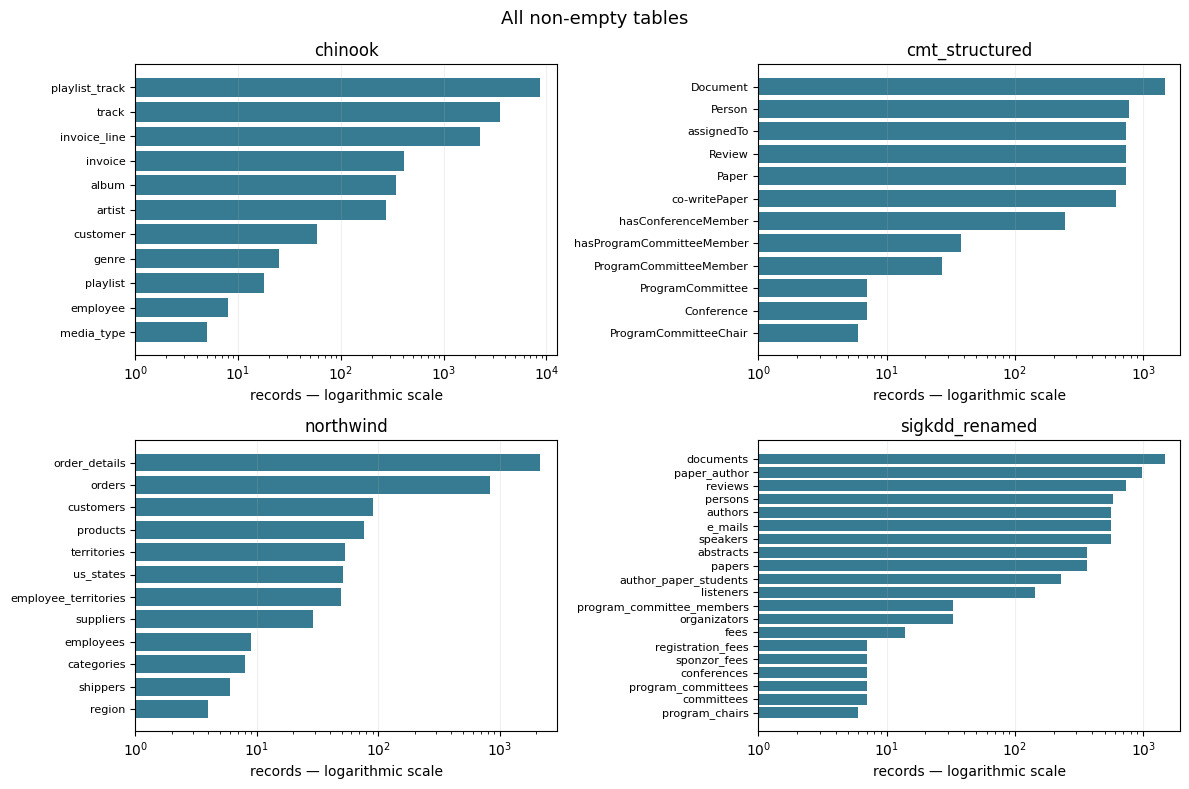

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, group) in zip(axes.flat, t.groupby('dataset')):
    largest = group[group.rows.gt(0)].sort_values('rows')
    ax.barh(largest.table, largest.rows, color='#367b91')
    ax.set(xscale='log', title=name, xlabel='records — logarithmic scale')
    ax.set_xlim(left=1)
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='x', alpha=.2)
fig.suptitle('All non-empty tables', fontsize=13)
fig.tight_layout()
fig.savefig(OUT/'table_sizes.png', dpi=150)
display(fig)
plt.close(fig)

## 3. Can instance data help the matcher?
Each profile contains the type, NULL percentage, distinct count, most frequent
values, and up to three examples. Examples are selected deterministically by
sorting, so they are not a representative sample of the distribution.
Full results: [columns.csv](results/columns.csv). Identifiers and synthetic strings
may carry little semantic information; we inspect actual examples rather than
assuming that every column will help.

In [5]:
usable = c.assign(nonempty=c.rows-c.nulls-c['empty']-c.whitespace)
availability = usable.groupby('dataset').agg(columns=('column','size'),
    with_values=('nonempty', lambda s: s.gt(0).sum()),
    at_least_3_distinct=('distinct', lambda s: s.ge(3).sum()),
    max_length=('max_length','max'))
display(availability)
examples = c[c.column.str.lower().str.contains('email|mail|title|reports_to|support_rep_id|name')]
examples = examples[examples.distinct.gt(0)].groupby('dataset', group_keys=False).head(2)
display(examples[['dataset','table','column','type','null_pct','distinct','examples']].round(2))

,columns,with_values,at_least_3_distinct,max_length
dataset,,,,
chinook,64,64,59,188
cmt_structured,85,34,27,191
northwind,92,88,82,448
sigkdd_renamed,93,35,35,191


,dataset,table,column,type,null_pct,distinct,examples
12,cmt_structured,Conference,name,character varying,0.0,4,"[""SIGXYZ"", ""XSWC"", ""YSWC""]"
20,cmt_structured,Paper,title,character varying,0.0,316,"[""acridities unrealistic substituting surges preheats loggias"", ""acridi..."
86,sigkdd_renamed,abstracts,title,character varying,0.0,316,"[""acridities unrealistic substituting surges preheats loggias"", ""acridi..."
111,sigkdd_renamed,conferences,name_conference,character varying,0.0,4,"[""SIGXYZ"", ""XSWC"", ""YSWC""]"
179,chinook,album,title,character varying,0.0,347,"[""...And Justice For All"", ""20th Century Masters - The Millennium Colle..."
182,chinook,artist,name,character varying,0.0,275,"[""A Cor Do Som"", ""AC/DC"", ""Aaron Copland & London Symphony Orchestra""]"
243,northwind,categories,category_name,character varying,0.0,8,"[""Beverages"", ""Condiments"", ""Confections""]"
251,northwind,customers,company_name,character varying,0.0,91,"[""Alfreds Futterkiste"", ""Ana Trujillo Emparedados y helados"", ""Antonio ..."


**Conclusion:** titles in both RODI scenarios contain very specific names, which probably won't help to improve matcher from instance data whereas Chinook and Northwind contain recognizable album,
artist, and category names.
For RODI, comparing schema only, statistics, and values will be particularly important.
For Chinook and Northwind this instance data addition might be valuable.

## 4. Ontologies and evaluation material
We count RDF triples, predicates used in triples, and declared properties separately.
For example, in `:acceptPaper rdf:type owl:ObjectProperty`, the predicate is `rdf:type`
and the declared property is `acceptPaper`. These counts need not be equal.
The absence of explicit instances does not imply an absence of ontology relationships.

We analyze TTL; OWL/XML is preserved as a source and is not counted as another dataset.
We do not perform OWL reasoning or prove equivalence of the two serializations.
Resource nodes are distinct IRIs and blank nodes in subject or object positions;
literals are counted separately. Label and comment counts cover classes and properties.

In [6]:
o = r['ontologies'].set_index('dataset')
display(o[['triples','predicates','classes','object_properties','data_properties',
           'named_individuals','explicit_class_instances']].rename(columns={
    'triples':'triples', 'predicates':'predicates', 'classes':'classes',
    'object_properties':'object prop.', 'data_properties':'data prop.',
    'named_individuals':'NamedIndividual', 'explicit_class_instances':'class instances'}))
display(o[['resource_nodes','literal_nodes','terms','labeled','commented','subclass_axioms']].rename(columns={
    'resource_nodes':'resource nodes', 'literal_nodes':'literals', 'terms':'terms',
    'labeled':'with label', 'commented':'with comment', 'subclass_axioms':'subClassOf'}))

,triples,predicates,classes,object prop.,data prop.,NamedIndividual,class instances
dataset,,,,,,,
cmt_structured,468,16,30,49,11,0,0
sigkdd_renamed,371,12,49,21,18,0,0


,resource nodes,literals,terms,with label,with comment,subClassOf
dataset,,,,,,
cmt_structured,126,103,90,89,12,33
sigkdd_renamed,122,84,88,0,84,49


The triple count describes the **ontology graph**, not a record graph or the target VKG.

CMT provides labels for 89/90 terms; SIGKDD doesn't provide labels, but gives comments for 84/88. Using only `label` would discard most of SIGKDD's
available descriptions.

## 6. Conclusions and next experiments
The numerical findings below come from the same execution as the tables.

In [7]:
full_null = c[c.rows.gt(0) & c.null_pct.eq(100)]
elapsed = time.perf_counter() - started
display(Markdown(f"""
- Verified **{len(t)} tables and {int(t.rows.sum()):,} records** across four databases.
- **{len(full_null)} columns** in non-empty tables contain only NULL;
  **{int(t.rows.eq(0).sum())} tables** are empty. These cases cannot provide value examples.
- **{len(r['queries'])} SQL–SPARQL pairs** are available for RODI.
  Results on two scenarios do not represent the entire benchmark.
"""))


- Verified **115 tables and 31,032 records** across four databases.
- **17 columns** in non-empty tables contain only NULL;
  **60 tables** are empty. These cases cannot provide value examples.
- **58 SQL–SPARQL pairs** are available for RODI.
  Results on two scenarios do not represent the entire benchmark.
